In [ ]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



In [ ]:
df = pd.read_csv("/mnt/d/Dev/AIML/Projects/hotel-booking-cancelation-model/data/hotel_bookings.csv.zip")
display(df.dtypes)

In [ ]:
print("Dataset shape: ", df.shape)
display(df.head())
df.info()
display(df.describe(include="all").T)

print("\nMissing Values")
display(df.isnull().sum().sort_values(ascending=False))
print("\nDuplicate rows: ",df.duplicated().sum())

NameError: name 'df' is not defined

In [11]:
#target distribution 
print(df["is_canceled"].value_counts())

print(
    df['is_canceled']
    .value_counts(normalize=True)*100
)


is_canceled
0    75166
1    44224
Name: count, dtype: int64
is_canceled
0    62.958372
1    37.041628
Name: proportion, dtype: float64


In [ ]:
#dupliicate investigation
duplicates = df[df.duplicated(keep=False)]
print("Rows involved in duplicates: ", len(duplicates))

display(
    duplicates.sort_values(
        by=df.columns.tolist()
    ).head(10)
)

duplicates = df[df.duplicated(keep=False)]

print("Rows involved:", len(duplicates))
print("Exact duplicate groups:", df.duplicated().sum())

display(duplicates.head(10))

print("Exact duplicate rows:", df.duplicated().sum())
print("Rows involved in duplicates:",
      df.duplicated(keep=False).sum())

Rows involved in duplicates:  40165


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
40772,City Hotel,0,0,2015,August,32,7,0,2,2,...,No Deposit,14.0,NaN,0,Transient,75.0,0,1,Check-Out,2015-08-09
40802,City Hotel,0,0,2015,August,32,7,0,2,2,...,No Deposit,14.0,NaN,0,Transient,75.0,0,1,Check-Out,2015-08-09
40821,City Hotel,0,0,2015,August,32,8,0,1,2,...,No Deposit,9.0,NaN,0,Transient,89.0,0,1,Check-Out,2015-08-09
40838,City Hotel,0,0,2015,August,32,8,0,1,2,...,No Deposit,9.0,NaN,0,Transient,89.0,0,1,Check-Out,2015-08-09
76792,City Hotel,0,0,2015,August,33,10,1,0,2,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-08-11
76793,City Hotel,0,0,2015,August,33,10,1,0,2,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-08-11
76794,City Hotel,0,0,2015,August,33,10,1,0,2,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-08-11
41067,City Hotel,0,0,2015,August,33,11,0,1,1,...,No Deposit,NaN,38.0,0,Transient-Party,88.0,0,0,Check-Out,2015-08-12
41073,City Hotel,0,0,2015,August,33,11,0,1,1,...,No Deposit,NaN,38.0,0,Transient-Party,88.0,0,0,Check-Out,2015-08-12
41071,City Hotel,0,0,2015,August,33,11,0,1,2,...,No Deposit,NaN,NaN,0,Transient,80.0,0,0,Check-Out,2015-08-12


Rows involved: 40165
Exact duplicate groups: 31994


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
21,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,No Deposit,250.0,NaN,0,Transient,84.67,0,1,Check-Out,2015-07-07
22,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,No Deposit,250.0,NaN,0,Transient,84.67,0,1,Check-Out,2015-07-07
39,Resort Hotel,0,70,2015,July,27,2,2,3,2,...,No Deposit,250.0,NaN,0,Transient,137.00,0,1,Check-Out,2015-07-07
43,Resort Hotel,0,70,2015,July,27,2,2,3,2,...,No Deposit,250.0,NaN,0,Transient,137.00,0,1,Check-Out,2015-07-07
132,Resort Hotel,1,5,2015,July,28,5,1,0,2,...,No Deposit,240.0,NaN,0,Transient,97.00,0,0,Canceled,2015-07-01
138,Resort Hotel,1,5,2015,July,28,5,1,0,2,...,No Deposit,240.0,NaN,0,Transient,97.00,0,0,Canceled,2015-07-01
198,Resort Hotel,0,0,2015,July,28,7,0,1,1,...,No Deposit,240.0,NaN,0,Transient,109.80,0,3,Check-Out,2015-07-08
200,Resort Hotel,0,0,2015,July,28,7,0,1,1,...,No Deposit,240.0,NaN,0,Transient,109.80,0,3,Check-Out,2015-07-08


In [ ]:
#check suspicious numerical values 

print(df[["adults","children","babies"]].describe())
print("Negative ADR",(df["adr"]<0).sum())

print("Zero guests: ",(
    (df["adults"]==0)&
    (df["children"]==0)&
    (df["babies"]==0)
).sum())

# Guest count distributions
for col in ["adults", "children", "babies"]:
    print(f"\n{col.upper()}")
    print(df[col].value_counts().sort_index())

# Guest count summary
display(df[["adults", "children", "babies"]].describe())

zero_guests = df[
    (df["adults"] == 0) &
    (df["children"] == 0) &
    (df["babies"] == 0)
]
print("Bookings with zero guests:", len(zero_guests))

# ADR investigation
display(df["adr"].describe())
print("Negative ADR:", (df["adr"] < 0).sum())

# Guest count ranges
for col in ["adults", "children", "babies"]:
    print(f"\n{col}")
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())
    print("Distribution:")
    print(df[col].value_counts(dropna=False).sort_index())

# Bookings with zero guests
zero_guests = df[
    (df["adults"] == 0) &
    (df["children"] == 0) &
    (df["babies"] == 0)
]

print("\nZero-guest bookings:", len(zero_guests))

# Unusually high adult counts
display(df[df["adults"] > 10][
    ["hotel", "adults", "children", "babies"]
].head(10))

              adults       children         babies
count  119390.000000  119386.000000  119390.000000
mean        1.856403       0.103890       0.007949
std         0.579261       0.398561       0.097436
min         0.000000       0.000000       0.000000
25%         2.000000       0.000000       0.000000
50%         2.000000       0.000000       0.000000
75%         2.000000       0.000000       0.000000
max        55.000000      10.000000      10.000000
Negative ADR 1
Zero guests:  180


In [19]:
print("ADR statistics:")
print(df["adr"].describe())

print("Negative ADR records:")
display(df[df["adr"] < 0])

print("Zero ADR records:", (df["adr"] == 0).sum())

print("ADR above 1000:")
display(df[df["adr"] > 1000][
    ["hotel", "adults", "children", "babies", "adr"]
].head(10))

ADR statistics:
count    119390.000000
mean        101.831122
std          50.535790
min          -6.380000
25%          69.290000
50%          94.575000
75%         126.000000
max        5400.000000
Name: adr, dtype: float64
Negative ADR records:


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
14969,Resort Hotel,0,195,2017,March,10,5,4,6,2,...,No Deposit,273.0,NaN,0,Transient-Party,-6.38,0,0,Check-Out,2017-03-15


Zero ADR records: 1959
ADR above 1000:


,hotel,adults,children,babies,adr
48515,City Hotel,2,0.0,0,5400.0


In [20]:
#Check whether these records are concentrated among cancelled bookings:
print(
    zero_guests["is_canceled"].value_counts()
)

print(
    zero_guests["reservation_status"].value_counts()
)

is_canceled
0    155
1     25
Name: count, dtype: int64
reservation_status
Check-Out    155
Canceled      24
No-Show        1
Name: count, dtype: int64


In [21]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Rows involved in duplicates:",
      df.duplicated(keep=False).sum())

Exact duplicate rows: 31994
Rows involved in duplicates: 40165


In [22]:
display(df[df["adr"] < 0].T)

,14969
hotel,Resort Hotel
is_canceled,0
lead_time,195
arrival_date_year,2017
arrival_date_month,March
arrival_date_week_number,10
arrival_date_day_of_month,5
stays_in_weekend_nights,4
stays_in_week_nights,6
adults,2


In [23]:
display(
    df.nlargest(10, "adr")[
        ["hotel", "adults", "children", "babies",
         "stays_in_weekend_nights",
         "stays_in_week_nights", "adr"]
    ]
)

,hotel,adults,children,babies,stays_in_weekend_nights,stays_in_week_nights,adr
48515,City Hotel,2,0.0,0,0,1,5400.00
111403,City Hotel,1,0.0,0,0,1,510.00
15083,Resort Hotel,2,0.0,0,0,1,508.00
103912,City Hotel,2,2.0,0,1,1,451.50
13142,Resort Hotel,2,0.0,0,4,10,450.00
13391,Resort Hotel,2,2.0,0,2,4,437.00
39155,Resort Hotel,2,2.0,0,2,6,426.25
39568,Resort Hotel,3,1.0,0,2,3,402.00
39118,Resort Hotel,3,2.0,0,3,5,397.38
13323,Resort Hotel,2,1.0,0,2,8,392.00


In [24]:
print(df[["adults", "children", "babies"]].max())

adults      55.0
children    10.0
babies      10.0
dtype: float64


In [25]:
display(df.loc[48515].T)

hotel                                City Hotel
is_canceled                                   1
lead_time                                    35
arrival_date_year                          2016
arrival_date_month                        March
arrival_date_week_number                     13
arrival_date_day_of_month                    25
stays_in_weekend_nights                       0
stays_in_week_nights                          1
adults                                        2
children                                    0.0
babies                                        0
meal                                         BB
country                                     PRT
market_segment                    Offline TA/TO
distribution_channel                      TA/TO
is_repeated_guest                             0
previous_cancellations                        0
previous_bookings_not_canceled                0
reserved_room_type                            A
assigned_room_type                      

In [26]:
for col in ["company", "agent", "country", "children"]:
    print(f"\n{col}")
    print("Missing:", df[col].isna().sum())
    print("Missing percentage:",
          df[col].isna().mean() * 100)


company
Missing: 112593
Missing percentage: 94.30689337465449

agent
Missing: 16340
Missing percentage: 13.686238378423655

country
Missing: 488
Missing percentage: 0.40874445095904177

children
Missing: 4
Missing percentage: 0.003350364352123293


In [27]:
for col in ["adults", "children", "babies"]:
    print(f"\n{col}")
    print(df[col].value_counts().sort_index())


adults
adults
0       403
1     23027
2     89680
3      6202
4        62
5         2
6         1
10        1
20        2
26        5
27        2
40        1
50        1
55        1
Name: count, dtype: int64

children
children
0.0     110796
1.0       4861
2.0       3652
3.0         76
10.0         1
Name: count, dtype: int64

babies
babies
0     118473
1        900
2         15
9          1
10         1
Name: count, dtype: int64


In [28]:
display(
    df[df["adults"] > 10][
        ["hotel", "is_canceled", "adults", "children",
         "babies", "market_segment", "customer_type",
         "adr", "reservation_status"]
    ]
)

,hotel,is_canceled,adults,children,babies,market_segment,customer_type,adr,reservation_status
1539,Resort Hotel,1,40,0.0,0,Direct,Group,0.0,Canceled
1587,Resort Hotel,1,26,0.0,0,Offline TA/TO,Group,0.0,Canceled
1643,Resort Hotel,1,50,0.0,0,Direct,Group,0.0,Canceled
1752,Resort Hotel,1,26,0.0,0,Offline TA/TO,Group,0.0,Canceled
1884,Resort Hotel,1,26,0.0,0,Offline TA/TO,Group,0.0,Canceled
1917,Resort Hotel,1,27,0.0,0,Direct,Group,0.0,Canceled
1962,Resort Hotel,1,27,0.0,0,Direct,Group,0.0,Canceled
2003,Resort Hotel,1,26,0.0,0,Offline TA/TO,Group,0.0,Canceled
2164,Resort Hotel,1,26,0.0,0,Offline TA/TO,Group,0.0,Canceled
2173,Resort Hotel,1,55,0.0,0,Direct,Group,0.0,Canceled


In [29]:
for col in ["children", "babies"]:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False).sort_index())


children
children
0.0     110796
1.0       4861
2.0       3652
3.0         76
10.0         1
NaN          4
Name: count, dtype: int64

babies
babies
0     118473
1        900
2         15
9          1
10         1
Name: count, dtype: int64


In [30]:
display(df[df["children"].isna()].T)

,40600,40667,40679,41160
hotel,City Hotel,City Hotel,City Hotel,City Hotel
is_canceled,1,1,1,1
lead_time,2,1,1,8
arrival_date_year,2015,2015,2015,2015
arrival_date_month,August,August,August,August
arrival_date_week_number,32,32,32,33
arrival_date_day_of_month,3,5,5,13
stays_in_weekend_nights,1,0,0,2
stays_in_week_nights,0,2,2,5
adults,2,2,3,2


In [31]:
for col in ["agent", "company"]:
    print(f"\n{col} missingness by market segment:")
    print(
        df.groupby("market_segment")[col]
          .apply(lambda x: x.isna().mean() * 100)
    )


agent missingness by market segment:
market_segment
Aviation          89.451477
Complementary     86.137281
Corporate         86.761095
Direct            47.651912
Groups            20.937863
Offline TA/TO      1.606177
Online TA          0.616180
Undefined        100.000000
Name: agent, dtype: float64

company missingness by market segment:
market_segment
Aviation          10.548523
Complementary     57.873486
Corporate         15.561851
Direct            98.349992
Groups            92.978648
Offline TA/TO     99.562327
Online TA         99.830019
Undefined        100.000000
Name: company, dtype: float64


In [5]:
data = df.copy()

# Remove exact duplicate rows
data = data.drop_duplicates()

# Treat negative ADR as missing
data.loc[data["adr"] < 0, "adr"] = np.nan

# Create a flag for zero-guest bookings
data["zero_guest_booking"] = (
    (data["adults"] == 0) &
    (data["children"] == 0) &
    (data["babies"] == 0)
).astype(int)

print(data.shape)
print(data.isnull().sum()[data.isnull().sum() > 0])

(87396, 33)
children        4
country       452
agent       12193
company     82137
adr             1
dtype: int64


In [6]:
leakage_columns = [
    "reservation_status",
    "reservation_status_date",
    "assigned_room_type",
    "booking_changes"
]

data = data.drop(columns=leakage_columns)

X = data.drop(columns=["is_canceled"])
y = data["is_canceled"]

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print(X.shape)
print(X_train.shape)
print(X_test.shape)

(87396, 28)
(69916, 28)
(17480, 28)


In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify feature types
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns

categorical_features = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

# Numerical preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

Numerical features: 19
Categorical features: 9


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        min_samples_split=5,
        random_state=42,
        class_weight="balanced",
        
        n_jobs=-1
    )
}

In [15]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    print(f"\n{name}")
    print("Accuracy:", accuracy_score(y_test, predictions))
    print("Precision:", precision_score(y_test, predictions))
    print("Recall:", recall_score(y_test, predictions))
    print("F1:", f1_score(y_test, predictions))
    print("ROC-AUC:", roc_auc_score(y_test, probabilities))

    print(classification_report(y_test, predictions))

    trained_models[name] = pipeline


Logistic Regression
Accuracy: 0.74279176201373
Precision: 0.5217697618712132
Recall: 0.7706555671175859
F1: 0.6222483616198958
ROC-AUC: 0.83384125263994
              precision    recall  f1-score   support

           0       0.89      0.73      0.81     12675
           1       0.52      0.77      0.62      4805

    accuracy                           0.74     17480
   macro avg       0.71      0.75      0.71     17480
weighted avg       0.79      0.74      0.75     17480


Random Forest
Accuracy: 0.7924485125858124
Precision: 0.5834396710619595
Recall: 0.8563995837669095
F1: 0.694046213526733
ROC-AUC: 0.8960236111709738
              precision    recall  f1-score   support

           0       0.93      0.77      0.84     12675
           1       0.58      0.86      0.69      4805

    accuracy                           0.79     17480
   macro avg       0.76      0.81      0.77     17480
weighted avg       0.84      0.79      0.80     17480



[[9737 2938]
 [ 690 4115]]


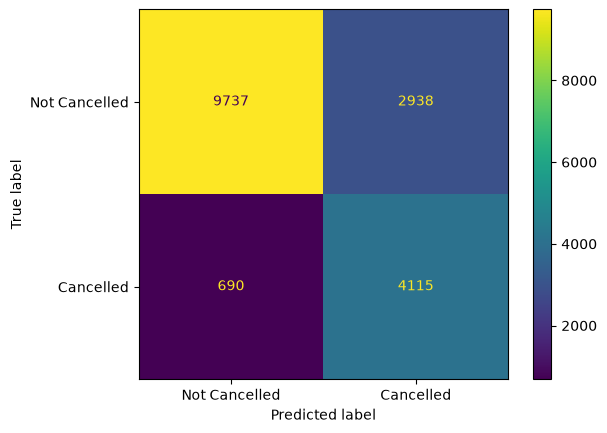

In [16]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

rf_model = trained_models["Random Forest"]

rf_predictions = rf_model.predict(X_test)

cm = confusion_matrix(y_test, rf_predictions)

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Cancelled", "Cancelled"]
).plot()

plt.show()

In [17]:
import pandas as pd

preprocessor_fitted = rf_model.named_steps["preprocessor"]
rf = rf_model.named_steps["model"]

feature_names = preprocessor_fitted.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(15))

,Feature,Importance
0,num__lead_time,0.122828
168,cat__country_PRT,0.095722
16,num__required_car_parking_spaces,0.073222
17,num__total_of_special_requests,0.067298
12,num__agent,0.061108
214,cat__market_segment_Online TA,0.053598
15,num__adr,0.050823
213,cat__market_segment_Offline TA/TO,0.029349
1,num__arrival_date_year,0.025643
5,num__stays_in_week_nights,0.025424


In [19]:

from sklearn.metrics import precision_score, recall_score, f1_score

rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:

    predictions = (
        rf_probabilities >= threshold
    ).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", precision_score(y_test, predictions))
    print("Recall:", recall_score(y_test, predictions))
    print("F1:", f1_score(y_test, predictions))


Threshold: 0.3
Precision: 0.4504820333041192
Recall: 0.9627471383975026
F1: 0.6137720578479501

Threshold: 0.4
Precision: 0.5107731305449936
Recall: 0.9225806451612903
F1: 0.6575200237318303

Threshold: 0.5
Precision: 0.5834396710619595
Recall: 0.8563995837669095
F1: 0.694046213526733

Threshold: 0.6
Precision: 0.7140082020289229
Recall: 0.6884495317377731
F1: 0.7009959737232464

Threshold: 0.7
Precision: 0.7792082394592855
Recall: 0.5038501560874089
F1: 0.6119817997977756


In [20]:
for col in ["agent", "company"]:
    data[col] = (
        data[col]
        .astype("Int64")
        .astype("string")
        .fillna("Unknown")
        .astype(object)
    )

In [21]:
from sklearn.model_selection import train_test_split

# Remove columns unavailable at booking creation
leakage_columns = [
    "reservation_status",
    "reservation_status_date",
    "assigned_room_type",
    "booking_changes"
]

data = data.drop(
    columns=[col for col in leakage_columns if col in data.columns]
)

X = data.drop(columns=["is_canceled"])
y = data["is_canceled"]

# Hold out the final test set
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Split training data again for validation
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Identify feature types
numeric_features = X_fit.select_dtypes(include=["number"]).columns
categorical_features = X_fit.select_dtypes(
    include=["object", "category", "str"]
).columns

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Agent categorical:", "agent" in categorical_features)
print("Company categorical:", "company" in categorical_features)
print("Training:", X_fit.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Numeric features: 17
Categorical features: 11
Agent categorical: True
Company categorical: True
Training: (55932, 28)
Validation: (13984, 28)
Test: (17480, 28)


In [22]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        min_samples_split=5,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

ValueError: Cannot use median strategy with non-numeric data:
could not convert string to float: 'Unknown'

In [23]:
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

print("Numeric:", len(numeric_features))
print("Categorical:", len(categorical_features))
print("Agent categorical:", "agent" in categorical_features)
print("Company categorical:", "company" in categorical_features)

Numeric: 17
Categorical: 11
Agent categorical: True
Company categorical: True


In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [25]:
rf_model.fit(X_train, y_train)

ValueError: Cannot use median strategy with non-numeric data:
could not convert string to float: 'Unknown'

In [26]:
print("agent in numeric:", "agent" in numeric_features)
print("company in numeric:", "company" in numeric_features)

print("agent in categorical:", "agent" in categorical_features)
print("company in categorical:", "company" in categorical_features)

agent in numeric: False
company in numeric: False
agent in categorical: True
company in categorical: True


In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier

# Numeric preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# New preprocessor
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# New model pipeline
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        min_samples_split=5,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# Train
rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](28,)","['hotel','lead_time','arrival_date_year',...,'required_car_parking_spaces', 'total_of_special_requests','zero_guest_booking']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,28
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'dr

In [28]:
val_probabilities = rf_model.predict_proba(X_val)[:, 1]

In [29]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

threshold_results = []

for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:

    predictions = (val_probabilities >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "F1": f1_score(y_val, predictions)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

,Threshold,Precision,Recall,F1
0,0.3,0.430771,0.997138,0.601632
1,0.4,0.515880,0.971904,0.674003
2,0.5,0.576740,0.912071,0.706641
3,0.6,0.771842,0.721644,0.745899
4,0.7,0.845670,0.454735,0.591440


In [30]:
best_threshold = threshold_df.loc[
    threshold_df["F1"].idxmax(),
    "Threshold"
]

print("Best validation threshold:", best_threshold)

Best validation threshold: 0.6


In [31]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

test_probabilities = rf_model.predict_proba(X_test)[:, 1]

test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

In [32]:
print("Accuracy:", accuracy_score(y_test, test_predictions))
print("Precision:", precision_score(y_test, test_predictions))
print("Recall:", recall_score(y_test, test_predictions))
print("F1 Score:", f1_score(y_test, test_predictions))
print("ROC-AUC:", roc_auc_score(y_test, test_probabilities))

Accuracy: 0.8310640732265446
Precision: 0.7141535615171137
Recall: 0.6426638917793964
F1 Score: 0.6765253587468507
ROC-AUC: 0.8856120370997502


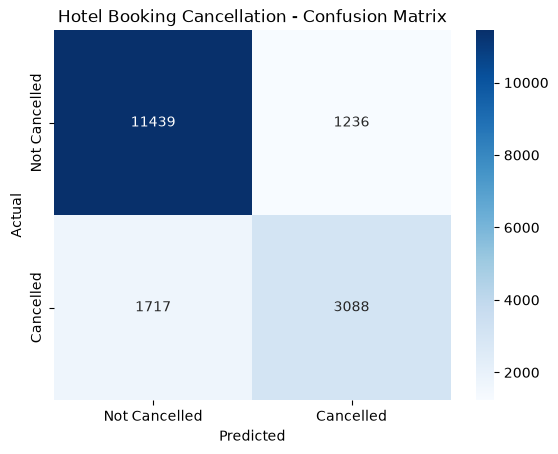

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, test_predictions)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Cancelled", "Cancelled"],
    yticklabels=["Not Cancelled", "Cancelled"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Hotel Booking Cancellation - Confusion Matrix")
plt.show()

In [34]:
print(classification_report(y_test, test_predictions))


              precision    recall  f1-score   support

           0       0.87      0.90      0.89     12675
           1       0.71      0.64      0.68      4805

    accuracy                           0.83     17480
   macro avg       0.79      0.77      0.78     17480
weighted avg       0.83      0.83      0.83     17480



In [35]:
import joblib

model_bundle = {
    "model": rf_model,
    "threshold": float(best_threshold),
    "features": X_train.columns.tolist(),
    "target": "is_canceled"
}

joblib.dump(model_bundle, "hotel_cancellation_model.joblib")

['hotel_cancellation_model.joblib']

In [36]:
import os

print(os.path.abspath("hotel_cancellation_model.joblib"))
print(os.path.exists("hotel_cancellation_model.joblib"))

/mnt/d/Dev/AIML/Projects/hotel-booking-cancelation-model/notebooks/hotel_cancellation_model.joblib
True
